# Historical Delay Analysis

Analysis of every station record collected by `automated_collection.py`.

The API returns every stop of every active train on each 30-minute call, so the same stop shows up in many collections. `get_unique_stops()` keeps one row per stop per train run (from the latest collection that saw it) and keeps only stops the train has already **departed**, so every delay below is an actual delay rather than an estimate for a future stop. A handful of records claiming departures over an hour early are API errors and are dropped.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from automated_collection import HistoricalDataManager

manager = HistoricalDataManager()
stops = manager.get_unique_stops(departed_only=True)
stops = stops[stops['departure_delay_minutes'] >= -60]

print(f"Departures covered: {stops['scheduled_departure'].min():%Y-%m-%d} to {stops['scheduled_departure'].max():%Y-%m-%d}")
print(f"Routes: {stops['route_name'].nunique()}, stations: {stops['station_code'].nunique()}")

Loaded 52568 records
9019 unique stops from 779 train runs
Departures covered: 2025-08-03 to 2025-10-09
Routes: 58, stations: 874


## Departure performance

How late trains leave each stop, using the same categories as the recent-data notebook.

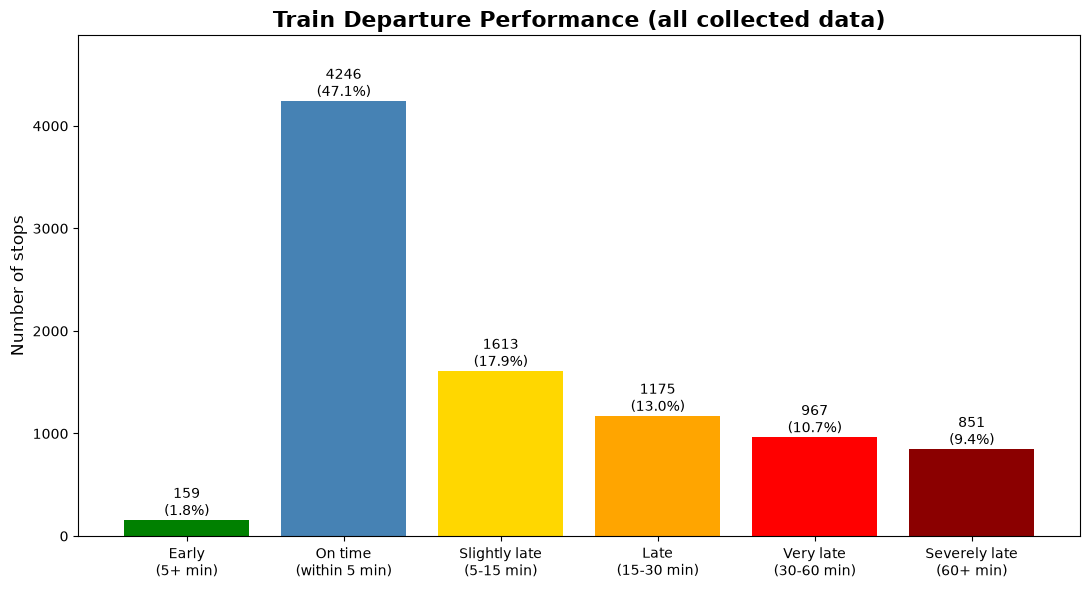

Departures 15+ minutes late: 34.0%
Median departure delay: 6.0 minutes


In [2]:
DELAY_BINS = [-60, -5, 5, 15, 30, 60, float('inf')]
DELAY_LABELS = ['Early\n(5+ min)', 'On time\n(within 5 min)', 'Slightly late\n(5-15 min)',
                'Late\n(15-30 min)', 'Very late\n(30-60 min)', 'Severely late\n(60+ min)']
DELAY_COLORS = ['green', 'steelblue', 'gold', 'orange', 'red', 'darkred']


def plot_departure_performance(delays, title, save_path=None):
  categories = pd.cut(delays, bins=DELAY_BINS, labels=DELAY_LABELS)
  counts = categories.value_counts().reindex(DELAY_LABELS, fill_value=0)
  percents = counts / counts.sum() * 100

  fig, ax = plt.subplots(figsize=(11, 6))
  bars = ax.bar(counts.index, counts.values, color=DELAY_COLORS)
  ax.bar_label(bars, labels=[f'{c}\n({p:.1f}%)' for c, p in zip(counts, percents)])
  ax.set_title(title, fontsize=16, fontweight='bold')
  ax.set_ylabel('Number of stops', fontsize=12)
  ax.margins(y=0.15)
  fig.tight_layout()
  if save_path:
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
  plt.show()
  return percents


percents = plot_departure_performance(
  stops['departure_delay_minutes'],
  'Train Departure Performance (all collected data)',
  save_path='images/departure_performance_distribution.png',
)
late_15 = (stops['departure_delay_minutes'] >= 15).mean() * 100
print(f"Departures 15+ minutes late: {late_15:.1f}%")
print(f"Median departure delay: {stops['departure_delay_minutes'].median():.1f} minutes")

## Average delay by route

Routes with at least 50 departed stops in the data. The dashed lines mark the ±5 minute on-time window.

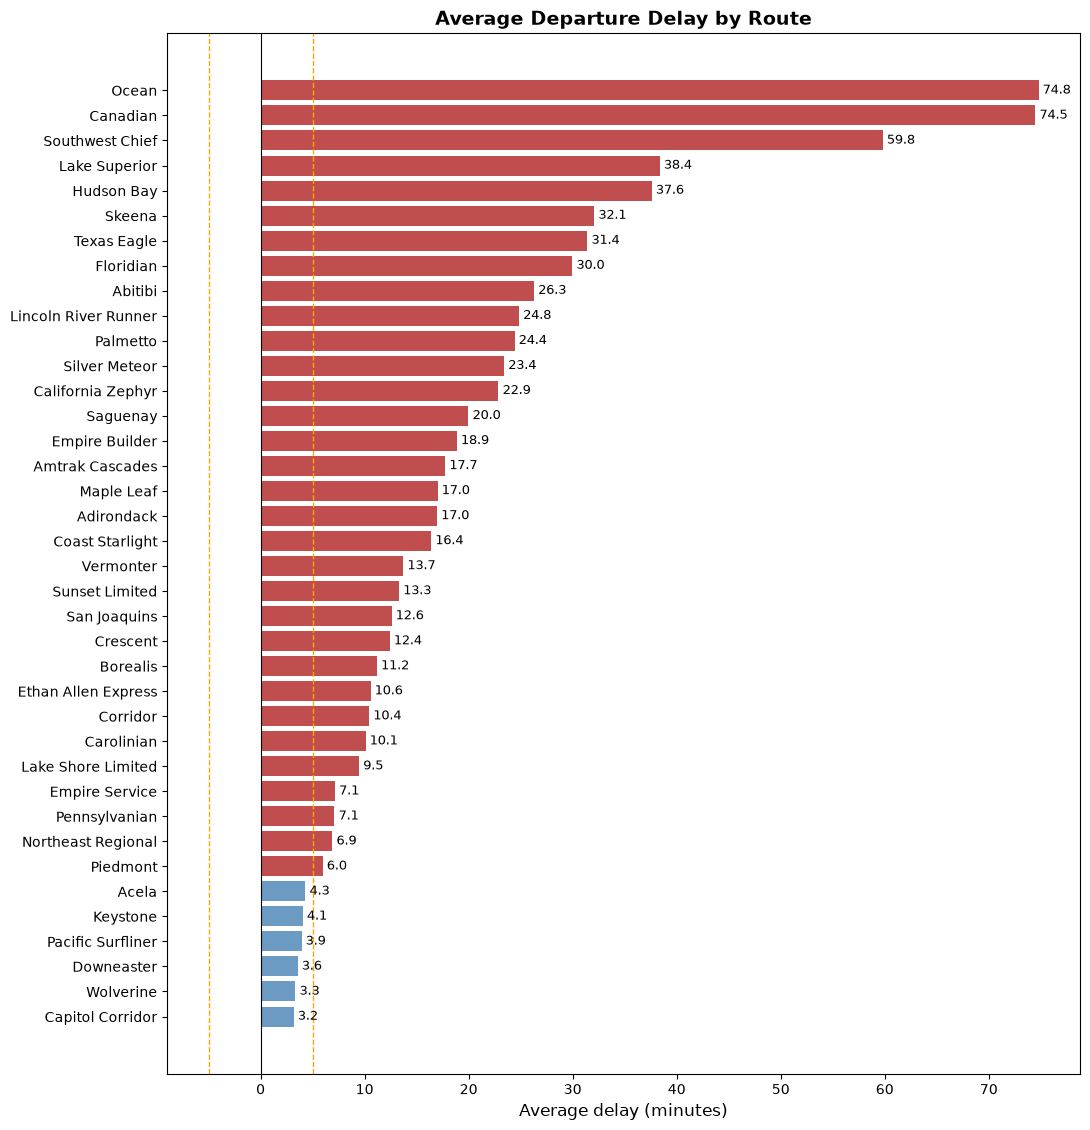

38 routes shown
Most delayed: Ocean (74.8 min average)
Most punctual: Capitol Corridor (3.2 min average)


In [3]:
route_delays = (stops.groupby('route_name')['departure_delay_minutes']
                .agg(['mean', 'median', 'count'])
                .query('count >= 50')
                .sort_values('mean'))

fig, ax = plt.subplots(figsize=(11, max(6, len(route_delays) * 0.3)))
colors = ['steelblue' if abs(m) <= 5 else ('green' if m < 0 else 'firebrick') for m in route_delays['mean']]
bars = ax.barh(route_delays.index, route_delays['mean'], color=colors, alpha=0.8)
ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
ax.axvline(0, color='black', linewidth=0.8)
for x in (-5, 5):
  ax.axvline(x, color='orange', linestyle='--', linewidth=1)
ax.set_title('Average Departure Delay by Route', fontsize=14, fontweight='bold')
ax.set_xlabel('Average delay (minutes)', fontsize=12)
fig.tight_layout()
fig.savefig('images/average_route_delays.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"{len(route_delays)} routes shown")
print(f"Most delayed: {route_delays.index[-1]} ({route_delays['mean'].iloc[-1]:.1f} min average)")
print(f"Most punctual: {route_delays['mean'].abs().idxmin()} ({route_delays['mean'].loc[route_delays['mean'].abs().idxmin()]:.1f} min average)")

## Delays build up along a route

A train's delay at a stop depends heavily on how far into its trip it is. This is why stop number is one of the most important features in `models.py`.

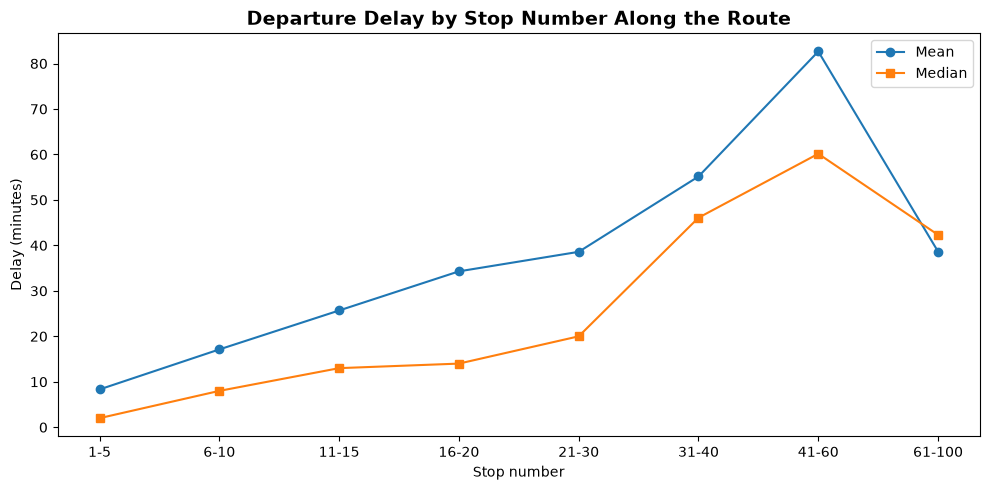

,median,mean,count
stop_group,,,
"(0, 5]",2.0,8.3,3525
"(5, 10]",8.0,17.1,2348
"(10, 15]",13.0,25.7,1197
"(15, 20]",14.0,34.3,714
"(20, 30]",20.0,38.6,747
"(30, 40]",46.1,55.2,284
"(40, 60]",60.2,82.7,177
"(60, 100]",42.3,38.6,19


In [4]:
stop_bins = [0, 5, 10, 15, 20, 30, 40, 60, 100]
by_stop = (stops.assign(stop_group=pd.cut(stops['stop_number'], stop_bins))
                .groupby('stop_group', observed=True)['departure_delay_minutes']
                .agg(['median', 'mean', 'count']))

fig, ax = plt.subplots(figsize=(10, 5))
labels = [f'{int(b.left) + 1}-{int(b.right)}' for b in by_stop.index]
ax.plot(labels, by_stop['mean'], marker='o', label='Mean')
ax.plot(labels, by_stop['median'], marker='s', label='Median')
ax.set_title('Departure Delay by Stop Number Along the Route', fontsize=14, fontweight='bold')
ax.set_xlabel('Stop number')
ax.set_ylabel('Delay (minutes)')
ax.legend()
fig.tight_layout()
plt.show()
by_stop.round(1)